# PLA Box-Behnken DoE Notebook

Three-level response-surface design, measurements, repeatability, quadratic regression, ANOVA, Pareto, main effects, and surface/contour plots.


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from pla_doe_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS,
    FD_I_LEVELS,
    FD_II_LEVELS,
    IRONING_FIXED_SETTINGS,
    IRONING_LEVELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_HYDROSTATIC_MEASUREMENTS,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_HYDROSTATIC_MEASUREMENTS,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_RUNS,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from DoE_old_scale import (
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    FD_I_OLD_SCALE_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    FACTOR_COLORS,
    build_mass_measurements,
    build_response_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_model_anova_table,
    build_term_significance_table,
    build_error_comparison_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_pure_error_from_replicates,
    calculate_measurement_error_from_repeated_columns,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    format_quadratic_model_formula,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_quadratic_interaction_profiles,
    plot_model_anova,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_screening_response_contours,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_combined_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_augmented_model_pareto,
    plot_augmented_main_effects,
    plot_augmented_observed_vs_predicted,
    plot_augmented_residuals,
    plot_screening_half_normal,
    plot_mass_measurements,
    plot_response_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
    plot_interaction_mean_matrix,
)
from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving("notebook_figures")
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


In [2]:
DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## 1) DoE Matrix


### Extra Confirmation And Optimization Candidate Runs


#### 2-Factor 3-Level Candidate Matrix


In [53]:
# 2-parameter option: 9 runs.
# This is a full 3 x 3 grid and does not use Box-Behnken.
# Levels are loaded from the compact experiment dictionaries in ffd_measurements.py.

extra_run_9_real = pd.MultiIndex.from_product(
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.values(),
    names=EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS.keys(),
).to_frame(index=False)
extra_run_9_real.index += 1
extra_run_9_real.index.name = "Run"

display(extra_run_9_real)


,B_nozzle_temp,D_line_width
Run,,
1,225,0.62
2,225,0.70
3,225,0.80
4,230,0.62
5,230,0.70
6,230,0.80
7,235,0.62
8,235,0.70
9,235,0.80


#### 3-Factor Box-Behnken Candidate Matrix


In [54]:
# 3-parameter option: 15 runs.
# Box-Behnken needs exactly 3 factors, so keep layer height included here.

# Levels are loaded from the compact experiment dictionaries in ffd_measurements.py.

extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    center_repeats=3,
)

display(extra_run_15_coded)
display(extra_run_15_real)


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,0,-1,-1
2,0,-1,1
3,0,1,-1
4,0,1,1
5,-1,0,-1
6,-1,0,1
7,1,0,-1
8,1,0,1
9,-1,-1,0


,B_nozzle_temp,D_line_width,E_layer_height
Run,,,
1,230,0.62,0.10
2,230,0.62,0.14
3,230,0.80,0.10
4,230,0.80,0.14
5,225,0.70,0.10
6,225,0.70,0.14
7,235,0.70,0.10
8,235,0.70,0.14
9,225,0.62,0.12


## 2) Measurements


### Extra-Run Mass Measurements


,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_mean_g,mass_std_g
0,LD,NaN,None,None,None,NaN,NaN
1,HD,NaN,None,None,None,NaN,NaN
2,E1,88.964,None,None,None,89.0,NaN
3,E2,NaN,None,None,None,NaN,NaN
4,E3,NaN,None,None,None,NaN,NaN
5,E4,NaN,None,None,None,NaN,NaN
6,E5,NaN,None,None,None,NaN,NaN
7,E6,NaN,None,None,None,NaN,NaN


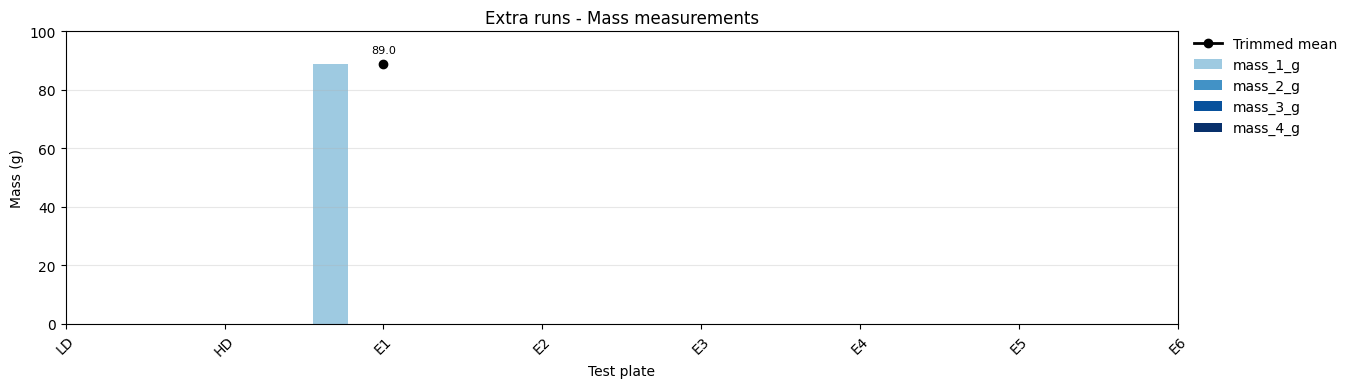

In [55]:
extra_run_mass_measurements_g, extra_run_mass_columns = build_mass_measurements(
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    run_labels=EXTRA_RUN_LABELS,
)

display(extra_run_mass_measurements_g[[
    "run",
    *extra_run_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    extra_run_mass_measurements_g,
    extra_run_mass_columns,
    y_min=0,
    y_max=100,
    mean_label="Trimmed mean",
    experiment="Extra runs",
)

### Box-Behnken Mass Measurements From New Scale


,run,mass_1_g,mass_2_g,mass_mean_g,mass_std_g
0,B1,89.090,89.100,89.1,0.007071
1,B2,89.015,89.022,89.0,0.004950
2,B3,88.986,88.996,89.0,0.007071
3,B4,89.171,89.183,89.2,0.008485
4,B5,89.313,89.316,89.3,0.002121
5,B6,89.789,89.796,89.8,0.004950
6,B7,89.720,89.730,89.7,0.007071
7,B8,89.306,89.312,89.3,0.004243
8,B9,88.868,88.863,88.9,0.003536
9,B10,89.093,89.105,89.1,0.008485


,runs_with_repeated_measurements,mean_measurement_std_g,rms_measurement_uncertainty_g,max_measurement_std_g
0,15,0.0058,0.0063,0.0092


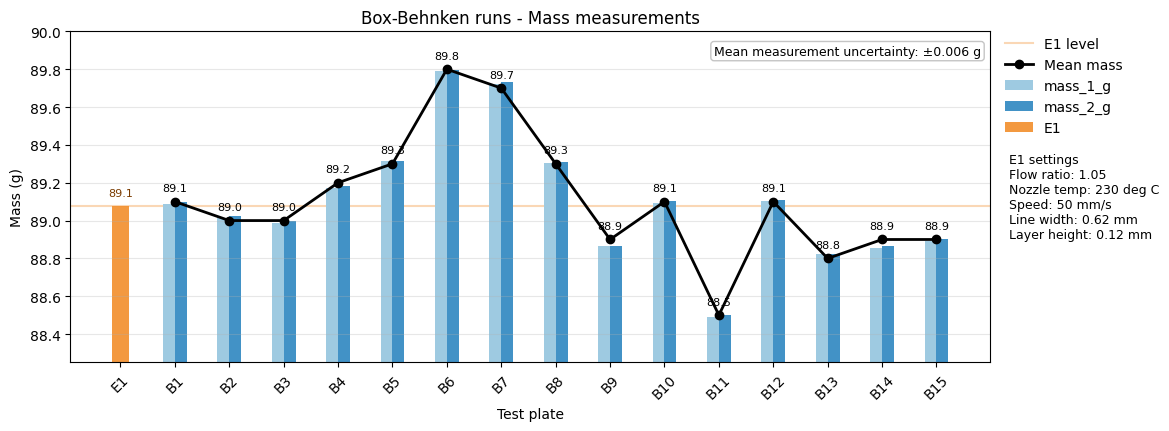

In [56]:
box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
)

display(box_behnken_mass_measurements_g[[
    "run",
    *box_behnken_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])

box_behnken_repeated_measurements_g = box_behnken_mass_measurements_g.dropna(
    subset=["mass_std_g"]
)
box_behnken_measurement_uncertainty_summary = pd.DataFrame([{
    "runs_with_repeated_measurements": len(box_behnken_repeated_measurements_g),
    "mean_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].mean(),
    "rms_measurement_uncertainty_g": (
        (box_behnken_repeated_measurements_g["mass_std_g"] ** 2).mean() ** 0.5
    ),
    "max_measurement_std_g": box_behnken_repeated_measurements_g["mass_std_g"].max(),
}])
display(box_behnken_measurement_uncertainty_summary.round(4))

e1_reference_mass_g = 89.077

plot_mass_measurements(
    box_behnken_mass_measurements_g,
    box_behnken_mass_columns,
    y_min=88.25,
    y_max=90,
    mean_label="Mean mass",
    experiment="Box-Behnken runs",
    reference_mass_g=e1_reference_mass_g,
    reference_label="E1",
    reference_details=(
        "E1 settings\n"
        "Flow ratio: 1.05\n"
        "Nozzle temp: 230 deg C\n"
        "Speed: 50 mm/s\n"
        "Line width: 0.62 mm\n"
        "Layer height: 0.12 mm"
    ),
)


### FD_II and Box-Behnken Combined Mass Comparison


This plot combines the FD_II RR runs and Box-Behnken runs because they use the same specimen geometry. Only runs with a mean mass above 80 g are included. Box-Behnken error bars show the standard deviation of its repeated scale measurements where available.


In [ ]:
# FD II reference data used only by the combined comparison plot.
FD_II_REFERENCE_RUN_LABELS = [f"RR{run_no}" for run_no in range(1, 17)]
FD_II_REFERENCE_MASS_MEASUREMENTS_G = {
    column: values[:16]
    for column, values in FD_II_MASS_MEASUREMENTS_G.items()
}
fd_II_reference_mass_measurements_g, _ = build_mass_measurements(
    FD_II_REFERENCE_MASS_MEASUREMENTS_G,
    run_labels=FD_II_REFERENCE_RUN_LABELS,
)


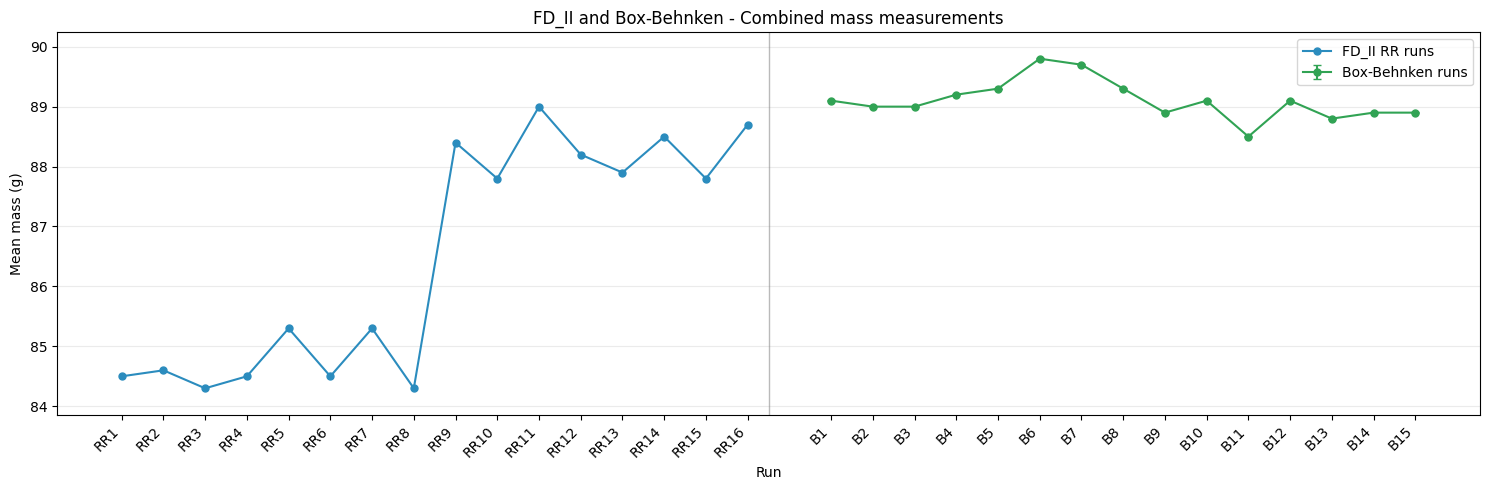

In [57]:
plot_combined_mass_measurement_sets(
    {
        "FD_II RR runs": fd_II_reference_mass_measurements_g,
        "Box-Behnken runs": box_behnken_mass_measurements_g,
    },
    minimum_mass=80,
    experiment="FD_II and Box-Behnken",
)


## 3) Response-Surface Analysis


### Box-Behnken Response-Surface Analysis


The surface/contour plots visualize the fitted quadratic model. Each figure shows two factors changing across their real setting range while the third factor is held at the middle level. The 3D-style surface shows the predicted mass height; the 2D contour plot is the same surface viewed from above, where contour lines connect settings with equal predicted mass. Red points mark measured runs that lie on that slice.


The Box-Behnken analysis below uses only the new mass measurements. A quadratic response-surface model is fitted as `mass = b0 + b1*x1 + b2*x2 + b3*x3 + b11*x1^2 + b22*x2^2 + b33*x3^2 + b12*x1*x2 + b13*x1*x3 + b23*x2*x3`, where the `x` values are the coded factor levels. The center-point repeats estimate print-to-print repeatability at identical settings.


In [58]:
if "extra_run_15_coded" not in globals():
    extra_run_15_coded, extra_run_15_real = create_box_behnken_design(
        EXTRA_RUN_BOX_BEHNKEN_LEVELS,
        center_repeats=3,
    )

if "box_behnken_mass_measurements_g" not in globals():
    box_behnken_mass_measurements_g, box_behnken_mass_columns = build_mass_measurements(
        BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
        run_labels=BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    )

box_behnken_result_matrix = build_result_matrix(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_result_matrix.dropna(subset=["mass_mean_g"]))


,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g
Run,,,,
1,0,-1,-1,89.1
2,0,-1,1,89.0
3,0,1,-1,89.0
4,0,1,1,89.2
5,-1,0,-1,89.3
6,-1,0,1,89.8
7,1,0,-1,89.7
8,1,0,1,89.3
9,-1,-1,0,88.9


,B_nozzle_temp,D_line_width,E_layer_height,run,mass_mean_g,mass_std_g,difference_from_center_mean_g,abs_difference_from_center_mean_g
Run,,,,,,,,
13,0,0,0,B13,88.8,0.000,-0.067,0.067
14,0,0,0,B14,88.9,0.006,0.033,0.033
15,0,0,0,B15,88.9,0.009,0.033,0.033


,center_repeats_with_data,center_mean_g,between_print_std_g,center_range_g,max_pair_difference_g,max_pair_difference_percent,mean_within_print_std_g
0,3,88.867,0.058,0.1,0.1,0.11,0.005


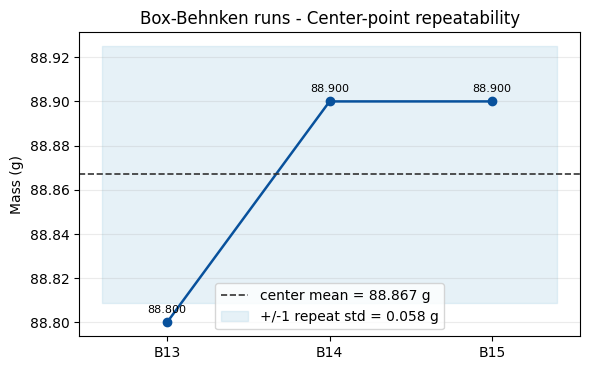

In [59]:
box_behnken_center_repeatability, box_behnken_repeatability_summary = calculate_center_point_repeatability(
    extra_run_15_coded,
    box_behnken_mass_measurements_g,
    response="mass_mean_g",
)

display(box_behnken_center_repeatability)
display(box_behnken_repeatability_summary)

plot_center_point_repeatability(
    box_behnken_center_repeatability,
    box_behnken_repeatability_summary,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)


The ANOVA table separates the variation explained by the quadratic Box-Behnken model from the unexplained residual variation. The Pareto plot ranks the fitted linear, quadratic, and interaction terms by their absolute standardized effect, so longer bars indicate terms that are more influential relative to the residual scatter.

The interaction profiles show the fitted response while one factor varies and a second factor is held at its low, center, or high level; the third factor is held at its center. Non-parallel or crossing profiles indicate interaction, while curved profiles also reflect the fitted quadratic terms. Points are measured runs on the corresponding slice.


,measured_runs,model_terms,rank,residual_df,r_squared,residual_std
0,15,10,10,5,0.9482,0.1258


,term,coefficient
0,Intercept,88.8667
1,B_nozzle_temp,-0.0625
2,D_line_width,0.1125
3,E_layer_height,0.0250
4,B_nozzle_temp^2,0.2417
5,D_line_width^2,-0.2083
6,E_layer_height^2,0.4167
7,B_nozzle_temp:D_line_width,0.1000
8,B_nozzle_temp:E_layer_height,-0.2250
9,D_line_width:E_layer_height,0.0750


Quadratic regression model in coded units (-1, 0, +1):
predicted_mass_g = 88.8667 - 0.0625*B_nozzle_temp + 0.1125*D_line_width + 0.0250*E_layer_height + 0.2417*B_nozzle_temp^2 - 0.2083*D_line_width^2 + 0.4167*E_layer_height^2 + 0.1000*B_nozzle_temp*D_line_width - 0.2250*B_nozzle_temp*E_layer_height + 0.0750*D_line_width*E_layer_height
Here B_nozzle_temp, D_line_width, and E_layer_height are coded factor levels; the observed-vs-predicted plot compares measured mass_mean_g with values calculated from this equation.


,run,B_nozzle_temp,D_line_width,E_layer_height,mass_mean_g,predicted_response,residual
Run,,,,,,,
1,1,0,-1,-1,89.1,89.012,0.088
2,2,0,-1,1,89.0,88.912,0.088
3,3,0,1,-1,89.0,89.087,-0.087
4,4,0,1,1,89.2,89.288,-0.087
5,5,-1,0,-1,89.3,89.337,-0.037
6,6,-1,0,1,89.8,89.838,-0.038
7,7,1,0,-1,89.7,89.662,0.038
8,8,1,0,1,89.3,89.262,0.038
9,9,-1,-1,0,88.9,88.950,-0.050


,replicate_group,n_group,group_mean,SS_pure_group,df_pure_group
6,B_nozzle_temp=0|D_line_width=0|E_layer_height=0,3,88.8667,0.0067,2


,replicate_groups,replicated_observations,SS_pure,df_pure,MSE_pure,s_pure
0,1,3,0.0067,2,0.0033,0.0577


,error_basis,SS,df,MSE,s
0,regression residual,0.0792,5.0,0.0158,0.1258
1,replicate pure error,0.0067,2.0,0.0033,0.0577


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,9,1.4502,0.1611,10.1766,0.01
1,Residual,5,0.0792,0.0158,NaN,NaN
2,Total,14,1.5293,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.9737,0.2190,0.0204,-3.0619,9.3750,0.0922,NaN,NaN,NaN,NaN
2,D_line_width,0.1125,0.0445,2.5288,6.3947,0.0526,0.0204,5.5114,30.3750,0.0314,NaN,NaN,NaN,NaN
3,E_layer_height,0.0250,0.0445,0.5620,0.3158,0.5984,0.0204,1.2247,1.5000,0.3453,NaN,NaN,NaN,NaN
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,13.6194,0.0141,0.0300,8.0432,64.6923,0.0151,NaN,NaN,NaN,NaN
5,D_line_width^2,-0.2083,0.0655,-3.1814,10.1215,0.0245,0.0300,-6.9338,48.0769,0.0202,NaN,NaN,NaN,NaN
6,E_layer_height^2,0.4167,0.0655,6.3628,40.4858,0.0014,0.0300,13.8675,192.3077,0.0052,NaN,NaN,NaN,NaN
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,2.5263,0.1728,0.0289,3.4641,12.0000,0.0742,NaN,NaN,NaN,NaN
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,12.7895,0.0159,0.0289,-7.7942,60.7500,0.0161,NaN,NaN,NaN,NaN
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.4211,0.2867,0.0289,2.5981,6.7500,0.1217,NaN,NaN,NaN,NaN


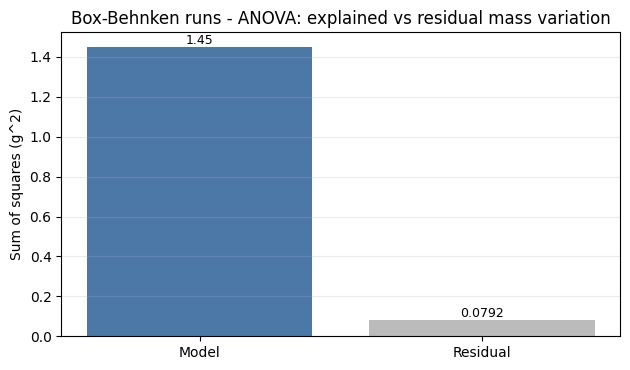

,term,coefficient,standard_error,t_value,absolute_t_value,F_value,p_value
0,Intercept,88.8667,0.0726,1223.2447,1223.2447,1.496328e+06,0.0000
1,B_nozzle_temp,-0.0625,0.0445,-1.4049,1.4049,1.973700e+00,0.2190
2,D_line_width,0.1125,0.0445,2.5288,2.5288,6.394700e+00,0.0526
3,E_layer_height,0.0250,0.0445,0.5620,0.5620,3.158000e-01,0.5984
4,B_nozzle_temp^2,0.2417,0.0655,3.6905,3.6905,1.361940e+01,0.0141
5,D_line_width^2,-0.2083,0.0655,-3.1814,3.1814,1.012150e+01,0.0245
6,E_layer_height^2,0.4167,0.0655,6.3628,6.3628,4.048580e+01,0.0014
7,B_nozzle_temp:D_line_width,0.1000,0.0629,1.5894,1.5894,2.526300e+00,0.1728
8,B_nozzle_temp:E_layer_height,-0.2250,0.0629,-3.5762,3.5762,1.278950e+01,0.0159
9,D_line_width:E_layer_height,0.0750,0.0629,1.1921,1.1921,1.421100e+00,0.2867


In [60]:
box_behnken_mass_model = fit_quadratic_response_surface(
    box_behnken_result_matrix,
    response="mass_mean_g",
)

display(box_behnken_mass_model["info_df"].round(4))
display(box_behnken_mass_model["coefficient_df"].round(4))
print("Quadratic regression model in coded units (-1, 0, +1):")
print(format_quadratic_model_formula(
    box_behnken_mass_model,
    response_label="predicted_mass_g",
    digits=4,
))
print(
    "Here B_nozzle_temp, D_line_width, and E_layer_height are coded factor levels; "
    "the observed-vs-predicted plot compares measured mass_mean_g with values calculated from this equation."
)
display(box_behnken_mass_model["fitted_df"].round(3))

box_behnken_replicate_observations, box_behnken_pure_error_groups, box_behnken_pure_error_summary = (
    calculate_pure_error_from_replicates(
        box_behnken_result_matrix,
        response="mass_mean_g",
        factor_cols=list(EXTRA_RUN_BOX_BEHNKEN_LEVELS),
    )
)
display(box_behnken_pure_error_groups.round(4))
display(box_behnken_pure_error_summary.round(4))
display(build_error_comparison_table(
    box_behnken_mass_model,
    box_behnken_pure_error_summary,
).round(4))

box_behnken_anova_table = build_quadratic_anova_table(box_behnken_mass_model)
display(box_behnken_anova_table.round(4))
display(
    build_term_significance_table(
        box_behnken_mass_model,
        pure_error_summary=box_behnken_pure_error_summary,
    ).round(4)
)
plot_model_anova(
    box_behnken_anova_table,
    response="mass_mean_g",
    experiment="Box-Behnken runs",
)
display(box_behnken_mass_model["term_statistics_df"].round(4))


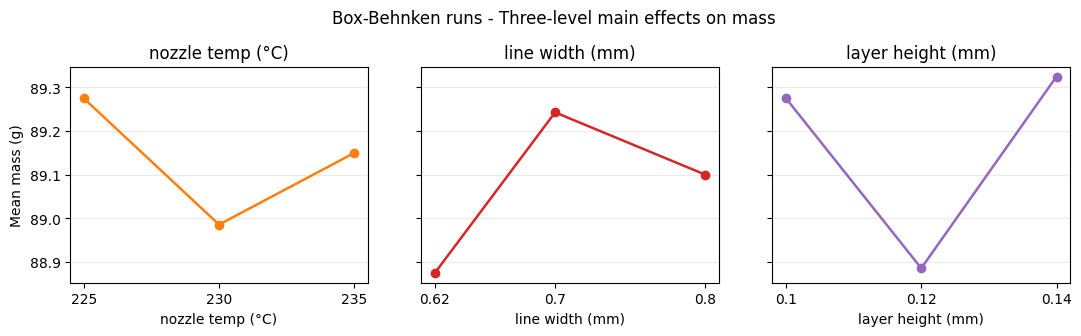

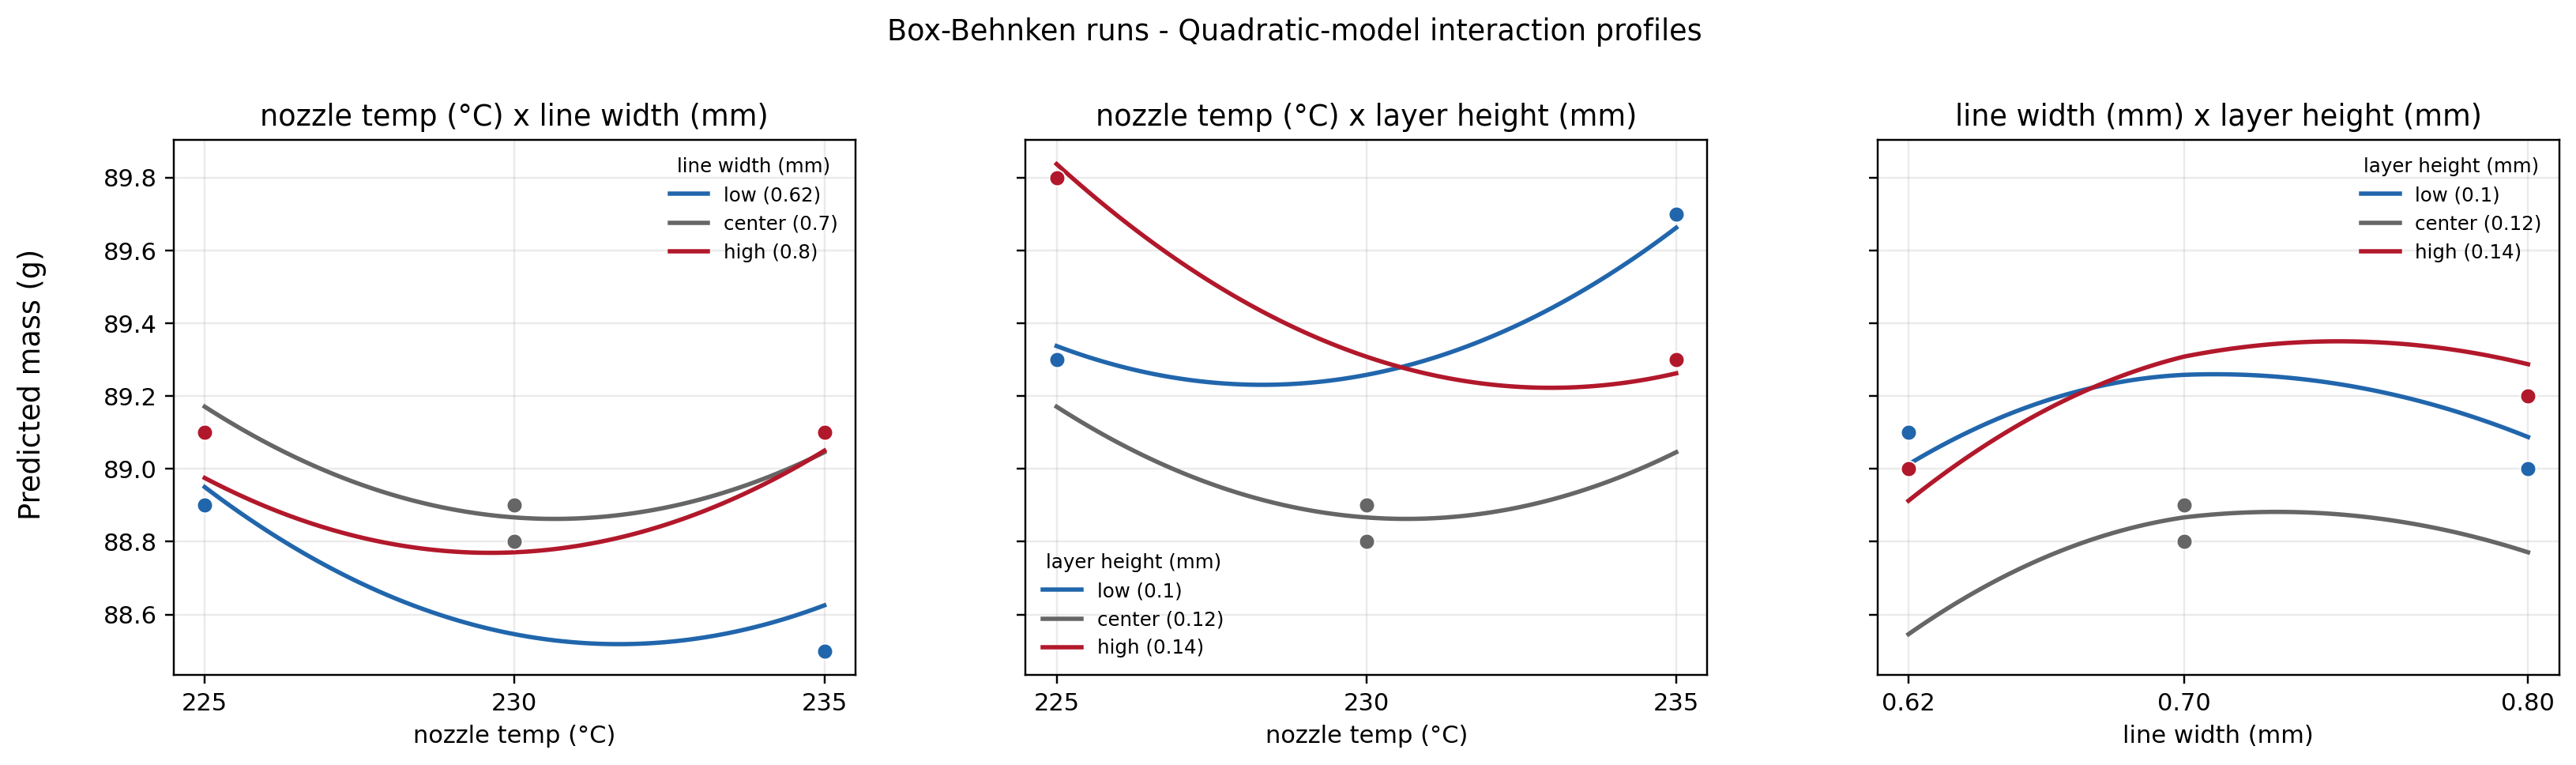

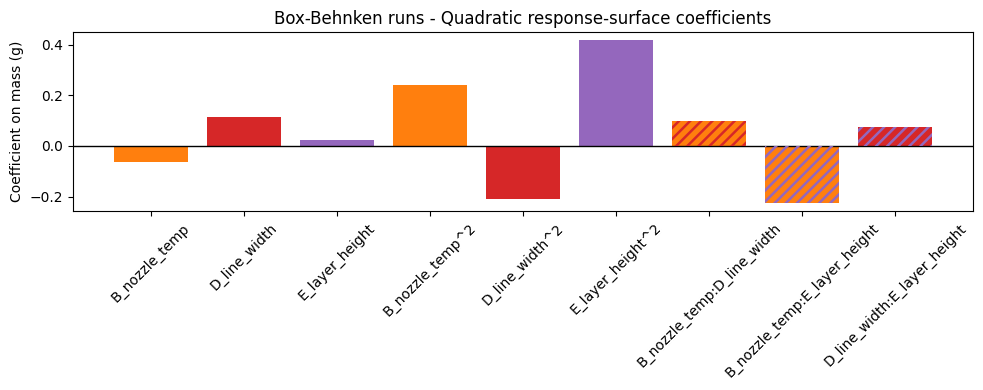

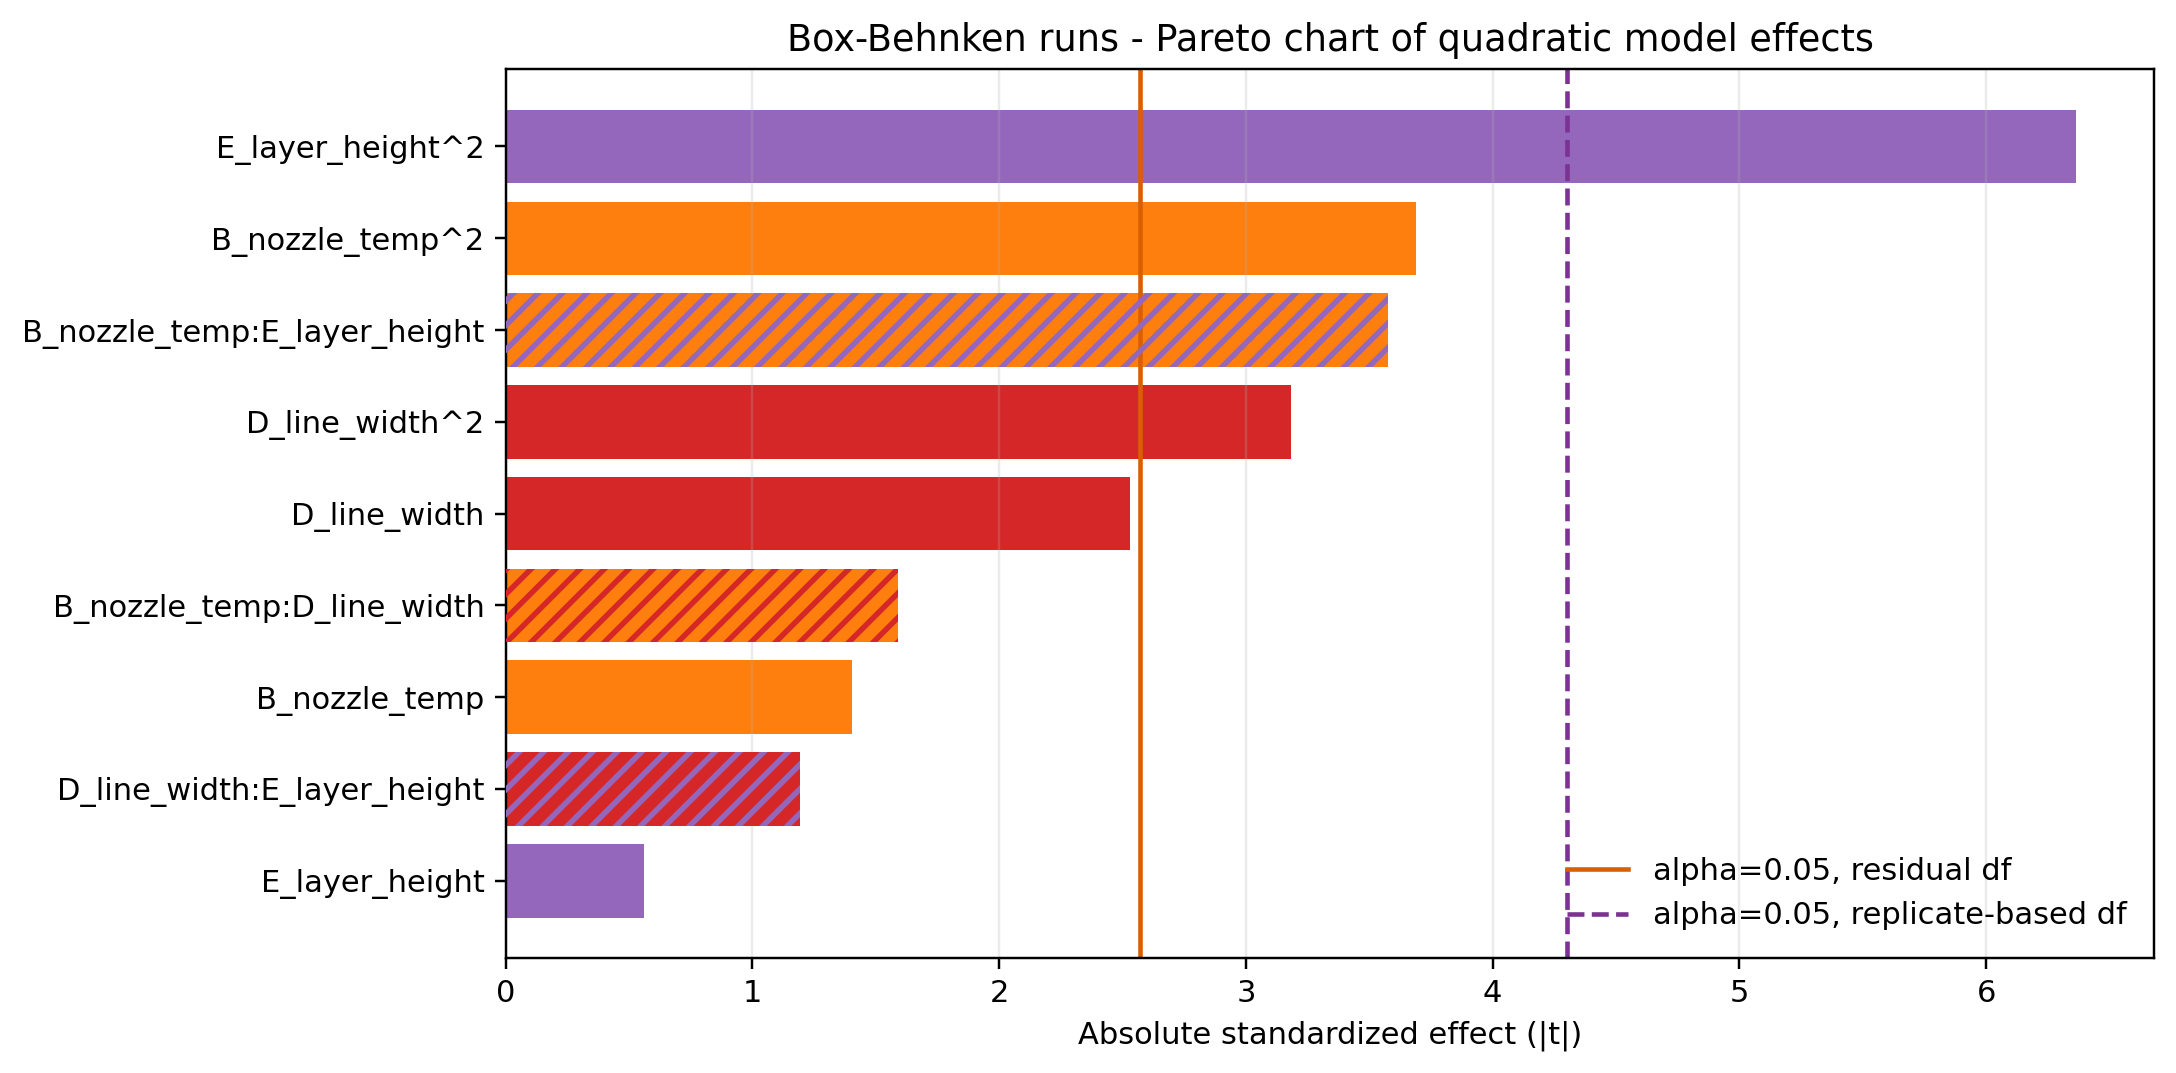

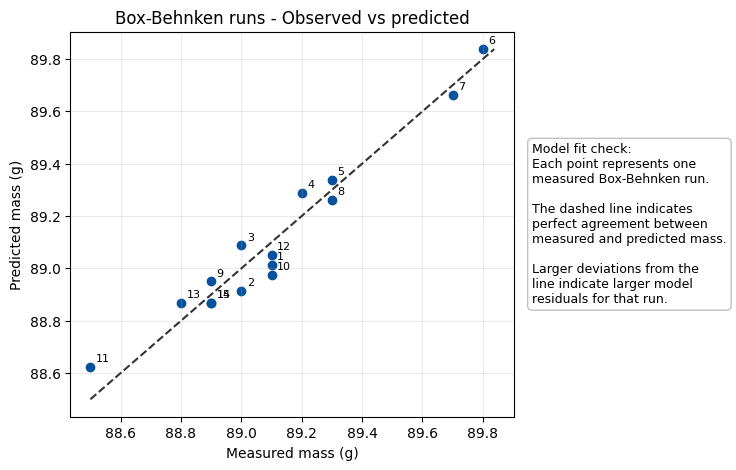

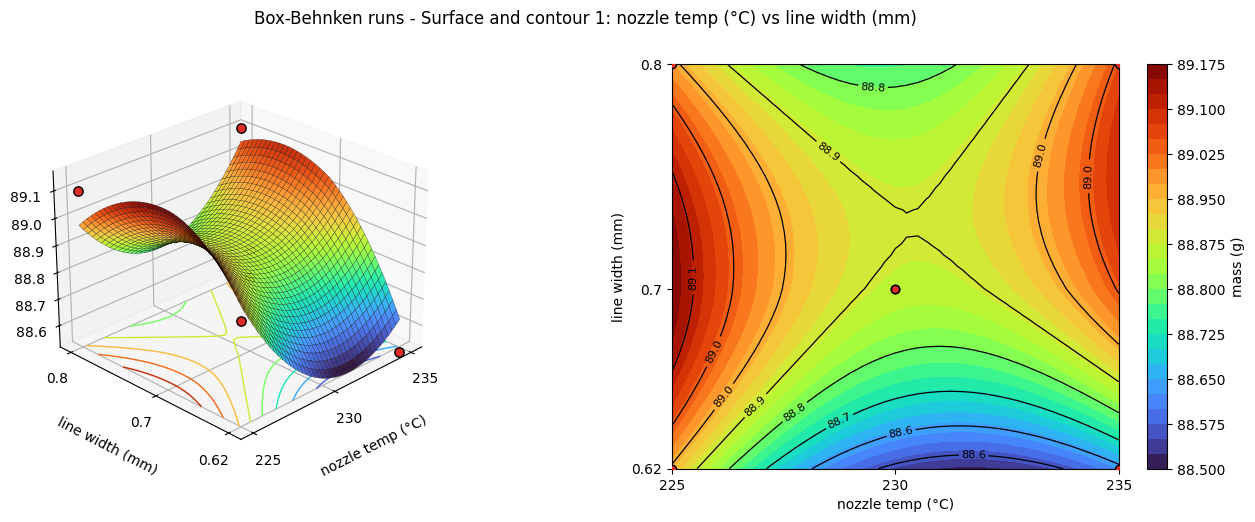

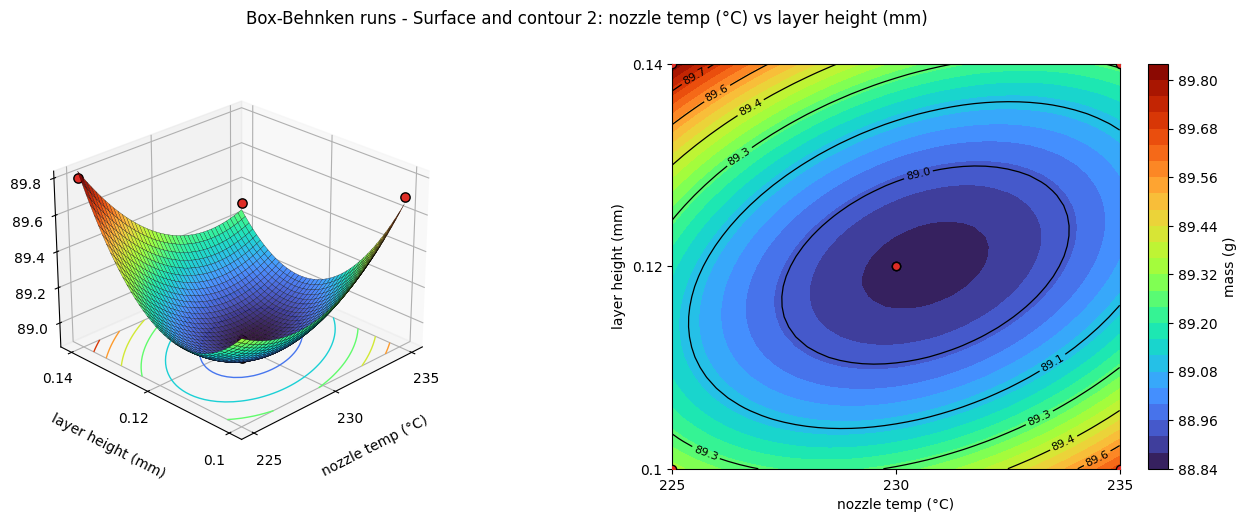

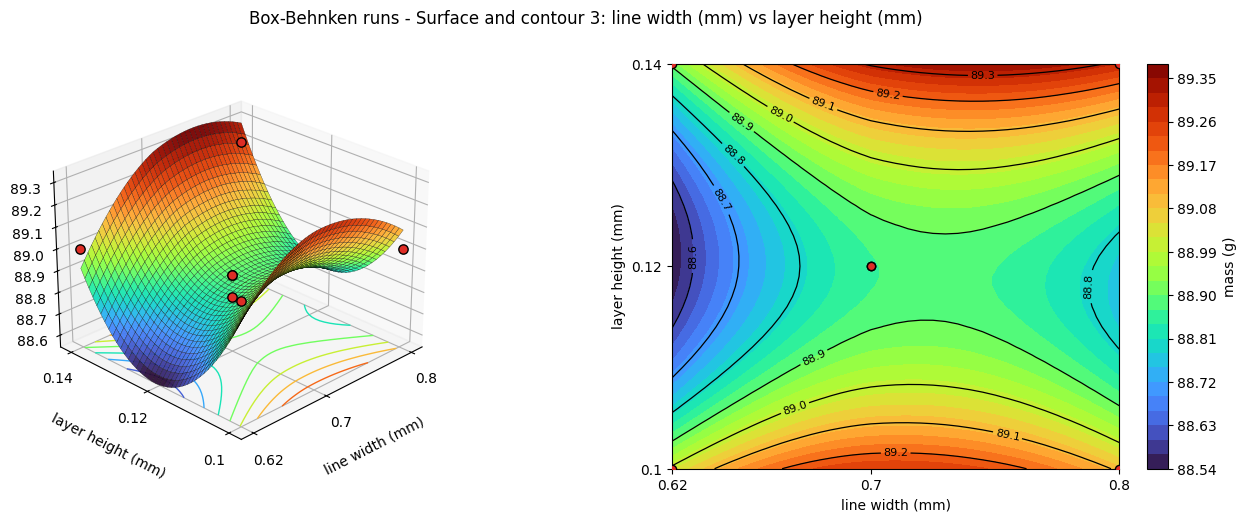

In [61]:
plot_three_level_main_effects(
    box_behnken_result_matrix,
    response="mass_mean_g",
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    experiment="Box-Behnken runs",
)

plot_quadratic_interaction_profiles(
    box_behnken_mass_model,
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    fixed_level=0,
    experiment="Box-Behnken runs",
)

plot_quadratic_coefficients(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_pareto(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
    pure_error_summary=box_behnken_pure_error_summary,
)

plot_quadratic_observed_vs_predicted(
    box_behnken_mass_model,
    experiment="Box-Behnken runs",
)

plot_quadratic_surface_and_contour_pairs(
    box_behnken_mass_model,
    levels=EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    fixed_level=0,
    experiment="Box-Behnken runs",
)
